In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ogstools as ot


In [ ]:
def calculate_function_k_s(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    k01=factors['k01']
    k02=factors['k02']

    sfmax= 1.0e-6
    splat = 
    prev=np.linspace(p1,p2,300)

    tanh_term = np.tanh((prev - pjack) / wr)
    c=(k02 - k01) * 0.5
    k_value = k01 + c* (1 + tanh_term)

    sf0=factors['sf0']
    beta_dimen=factors['b_dim']
    beta=pjack*beta_dimen

    X= np.sqrt(3)*np.sqrt(k_value)/k_value
    Y= c*(1-tanh_term**2)/wr
    s_value= sf0 + beta*X*Y 
    s_new = sf0 + beta*X*Y/(k_value)
    s_2 = s_value.copy()

    mask = (prev<0.8*pjack)
    p_s = prev[mask]
    s_s = s_value[mask]
    pstart= p_s[0]
    pend = p_s[-1]
    w_p = (pend-p_s)/(pend-pstart)

    s_adjusted = s_s + w_p*(sf0-s_s[0])
    s_zero = s_s[0]
    s_2[mask]= s_adjusted
    sa_min = s_2.min()

    s_2 = sf0 + ((s_2 - s_2.min())/(s_2.max()-s_2.min()))*(sfmax-sf0)

    sech2_ = (1.0 - tanh_term**2)
    dk_dp = Y
    f = 1.0/np.sqrt(k_value)
    df_dp = -0.5 * (k_value**(-1.5))*dk_dp

    g = sech2_
    dg_dp = -(2.0/wr)*tanh_term*sech2_

    C0 = beta *(  np.sqrt(3.0)* (k02 - k01)/(2.0*wr))
    term_A = C0*f*dg_dp
    term_B = C0*df_dp*g
    dsraw_dp = term_A + term_B
    A =  ((sfmax - sf0)/(s_value.max()-s_value.min()))

    ds_dp = A * dsraw_dp

    # dsnum = np.gradient(s_value, prev)
    # dsnum2 = np.gradient(s_2, prev)

    # keff=k_value*s_value/sf0
    val_dict = {
        "pstart": pstart,
        "pend": pend,
        "C0"  : C0,
        "s_zero" : s_zero,
        "A"      : A, 
        "sa_min" : sa_min       
    }

    return prev, s_new,s_value #s_2, ds_dp, val_dict

In [219]:
def calculate_function_k_s_2(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    # k01=factors['k01']
    # k02=factors['k02']
    

    s_plat = 1.0e-8
    factor_spike = 2
    hs = factor_spike *s_plat
    
    w_spike = 1e6

    beta = 1/w_spike
    alpha = 1.0/wr
  

    prev=np.linspace(p1,p2,300)
    sf0 = factors["sf0"]

    tanh_t1 = np.tanh( 0.5 * alpha * (prev - pjack)) 
    tanh_t2 = np.tanh ( beta * (prev - pjack))
    term_A = 0.5 * s_plat * ( 1 + tanh_t1)
    term_B = hs * ( 1 - tanh_t2**2)

    s_ab = sf0 + term_A + term_B

    ds_term_A = s_plat * ( 1- tanh_t1**2) * alpha / 4
    ds_term_B = -2 * hs * beta * tanh_t2 * (1 - tanh_t2**2)
    ds_ab = ds_term_A + ds_term_B

    ds_dp_ab_num = np.gradient(s_ab, prev)


    return prev, s_ab, ds_ab, ds_dp_ab_num

In [220]:
factors={
         'sf0':8.5e-11, 
         'pjack':3.5e6,
         'wr':0.5e6,
         'L':1.0,
         'k01':2e-14,
         'k02':1.0e-9,
         'sma':1.0e-10,
         'b_dim':1.0,
         'p1':1.0,
         'p2':12.0e6,
         'keff':1.0
}

In [221]:
prev, s_ab, ds1, ds2= calculate_function_k_s_2(factors)

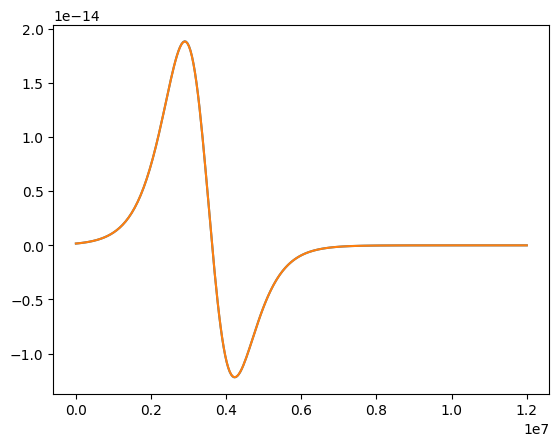

In [222]:
# plt.plot(prev, s_ab)
plt.plot(prev,ds1)
plt.plot(prev,ds2)

plt.pause(1)

In [4]:
# pvalue, s2, ds, dsnum, dsnum2= 
prev,s2,ds_dp, val_dict = calculate_function_k_s(factors)

In [5]:
# # plt.plot(pvalue, s2)
# plt.plot(pvalue, ds)
# # plt.plot(pvalue, dsnum)
# plt.plot(pvalue, dsnum2)

# plt.pause(1)

In [6]:
def temp_prj(prj_in, prj_out,val_dict: dict, factors:dict): 

    kf=(factors['k01'] +factors['k02'])/2
    s_xml, ds_xml = ogs_expr_ready(val_dict, factors)

    model = ot.Project(input_file=prj_in,output_file=prj_out)
    medium=1
    xpath_s=f".//media/medium[@id='{medium}']/properties/property[name='storage']/value/expression"
    xpath_ds=f".//media/medium[@id='{medium}']/properties/property[name='storage']/dvalue/expression"
    try:
        model.replace_text(s_xml,xpath=xpath_s)
        model.replace_text(ds_xml,xpath=xpath_ds)
        model.replace_medium_property_value(medium,'permeability',str(kf))

        nodes = model.tree.getroot().findall(xpath_s)
        print(f"found {len(nodes)} nodes(s) matchin xpath_s")

    except Exception as e:
        print(f"CRITICAL ERROR in PRJ update: {e}")
        raise # Stop the loop if the input file is not correctly updated

    model.write_input()

In [7]:
def wp_str(values):

    p = "liquid_phase_pressure"
    pstart = values["pstart"]
    pend = values["pend"]

    expresssion = (
                  f"((({p} < {pstart}) ? 1.0 : "
                  f"(({p} > {pend}) ? 0.0 : "
                  f"(({pend} - {p}) / ({pend} -{pstart})))))"
                  )
    return expresssion

def build_exp_ks(steps, final_output):
    """Form a list of (va_name, expression) tuples to formula
     Final format
        var variable := step_expression;
    """

    lines = [f"var {var_name} := {expr};" for var_name, expr in steps]
    lines.append(final_output)

    exp_xml = "\n".join(lines)

    return exp_xml

In [23]:
def  ogs_expr_ready(val_dict: dict, factors: dict) -> None:
    pjack = factors["pjack"]
    wr = factors["wr"]
    k01 = factors["k01"]
    k02 = factors["k02"]
    sf0 = factors["sf0"]
    C0 = val_dict["C0"]
    s_zero = val_dict["s_zero"]
    A = val_dict ["A"]
    sa_min = val_dict["sa_min"]


    u = f"((liquid_phase_pressure - {pjack}) / {wr})"
    tanh_u =  f"tanh({u})"
    sech2_u = f"(1.0 - ({tanh_u} * {tanh_u}))" 
    kp = f"({k01} + 0.5 * ({k02} - {k01}) * (1.0 + {tanh_u}))"
    s_raw = f"({sf0} + ({C0} / sqrt({kp})) * {sech2_u})"
    wp = wp_str(val_dict)
    s_a =  f"({s_raw} + {wp} * ({sf0} - {s_zero}))"
    final_s_expression = f"({sf0} + {A}* ({s_a} - {sa_min}))"

    s_xml = final_s_expression.replace("<", "&lt;").replace(">", "&gt;")

    c = f"(({k02} - {k01}) * 0.5)"
    kp_ds =  f"{k01} + {c}*(1.0 + {tanh_u})"
    dk_dp =  f"{c} *({sech2_u} / {wr})"
    f =  f"(1.0 / sqrt({kp}))"
    df_dp  = f"(-0.5 * pow({kp},-1.5)  * {dk_dp})"
    g = f"{sech2_u}"
    dg_dp =  f"((-2.0 / {wr}) * {tanh_u} * {g})"
    term_A = f"({C0} * {f} * {dg_dp})"
    term_B =  f"({C0} * {df_dp} * {g})"
    dsraw_dp =  f"({term_A} + {term_B})"
    final_ds_expression = f"{A} * {dsraw_dp}"

    ds_xml = final_ds_expression

    # steps_ds= [
    #     ("u", f"((liquid_phase_pressure - {pjack})/{wr})"),
    #     ("tanh_u", "tanh(u)" ),
    #     ("sech2_u", "1.0 - pow(tanh_u, 2)"),
    #     ("c", f"({k02 - k01})*0.5"),
    #     ("kp", f"{k01} + c*(1.0 + tanh_u)"),
    #     ("dk_dp", f"c *sech2_u/{wr}"),
    #     ("f", f"1.0/sqrt(kp)"),
    #     ("df_dp",f"-0.5 * (kp**(-1.5))*dk_dp"),
    #     ("g", "sech2_u"),
    #     ("dg_dp", f"-(2.0/{wr})*tanh_u*g"),
    #     ("term_A", f"{C0}*f*dg_dp"),
    #     ("term_B", f"{C0}*df_dp*g"),
    #     ("dsraw_dp", "term_A + term_B")
    # ]

    # final_ds_expression = "A * dsraw_dp"

    # ds_xml = build_exp_ks( steps_ds, final_ds_expression)

    return s_xml, ds_xml

In [24]:
s_xml, ds_xml = ogs_expr_ready(val_dict,factors)

print(s_xml)
print("\n",ds_xml)

(8.5e-10 + 0.0033855833600453652* (((8.5e-10 + (6.062056582934541e-09 / sqrt((2e-14 + 0.5 * (1e-09 - 2e-14) * (1.0 + tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)))))) * (1.0 - (tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)) * tanh(((liquid_phase_pressure - 3500000.0) / 500000.0))))) + (((liquid_phase_pressure &lt; 1.0) ? 1.0 : ((liquid_phase_pressure &gt; 2769231.5384615385) ? 0.0 : ((2769231.5384615385 - liquid_phase_pressure) / (2769231.5384615385 -1.0))))) * (8.5e-10 - 1.4055045491696171e-07)) - 8.500000000000109e-10))

 0.0033855833600453652 * ((6.062056582934541e-09 * (1.0 / sqrt((2e-14 + 0.5 * (1e-09 - 2e-14) * (1.0 + tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)))))) * ((-2.0 / 500000.0) * tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)) * (1.0 - (tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)) * tanh(((liquid_phase_pressure - 3500000.0) / 500000.0)))))) + (6.062056582934541e-09 * (-0.5 * pow((2e-14 + 0.5 * (1e-09 - 2e-14) * (1.0 + tanh(((li

# Testing expression


In [ ]:
def eval_exprtk_in_python(script_str, params):
    clean_script = script_str.replace("&lt;", "<").replace("&gt;", ">")

    lines = [line.strip() for line in clean_script.strip().splitlines() if line.strip()]
    statements, final_expr = lines[:-1], lines[-1]

    local_scope = {**params,
                   "tanh": np.tanh,
                    "pow": np.pow,
                    "sqrt": np.sqrt}

    for line in statements:
        line = line.rstrip(";").removeprefix("var ").strip()
        var_name, expr = line.split(":=", 1)
        var_name, expr = var_name.strip(), expr.strip()

        if "?" in expr and ":" in expr:
            expr = "np.where( liquid_phase_pressure < pstart, 1.0, np.where(liquid_phase_pressure > pend, 0.0, (pend-liquid_phase_pressure) / (pend - pstart)))"

        local_scope[var_name] = eval(expr, {"__builtins__": {}, "np": np}, local_scope)

    return eval(final_expr, {"__builtins__": {}}, local_scope)

# test
params = {
    "liquid_phase_pressure": prev,
    "pjack": factors["pjack"],
    "w": factors["wr"], 
    "k01": factors["k01"], 
    "k02": factors["k02"],
    "sf0": factors["sf0"], 
    "C0": val_dict["C0"], 
    "pstart": val_dict["pstart"], 
    "pend": val_dict["pend"],
    "s_zero": val_dict["s_zero"], 
    "A": val_dict["A"], 
    "sa_min": val_dict["sa_min"]
}

# exprtk_val_s = eval_exprtk_in_python(str(s_xml), params)
# print("Evaluated Script Result:", exprtk_val_s)

# exprtk_val_ds = eval_exprtk_in_python(str(ds_xml), params)
# print("Evaluated Script Result:", exprtk_val_ds)
import math 
import re
import ast

class ExprTkTop(ast.NodeTransformer):
    def visit_name(self, node):
        if node.id == "liquid_phase_pressure":
            return ast.Name(id="p", ctx=node.ctx)
        elif node.id in ("tanh", "sqrt"):
            return ast.Name(id=node.id, ctx=node.ctx)
        return self.generic_visit(node)

def exptrk_eval(exp_str, p_vec):
    expr_py = exp_str.replace("&lt;", "<")
    expr_py = expr_py.replace("&gt;", ">")
    expr_py = expr_py.replace("?", " if ").replace(":", " else ")
    expr_py = expr_py.replace("liquid_phase_pressure", "p")
    tree = ast.parse(expr_py, mode = "eval")

    transformed_tree = ExprTkTop().visit(tree)
    ast.fix_missing_locations(transformed_tree)

    compile_code = compile(transformed_tree, filename="<ogs_expr>", mode="eval")

    eval_namespace = {
        "p": float(p_vec), 
        "tanh": math.tanh,
        "sqrt": math.sqrt,
    }


    return eval(compile_code, eval_namespace)


In [25]:
p_array = np.linspace(1.0,12.0e6,300)
result_s = np.array([exptrk_eval(s_xml, p) for p in p_array])
result_ds = np.array([exptrk_eval(ds_xml, p) for p in p_array])

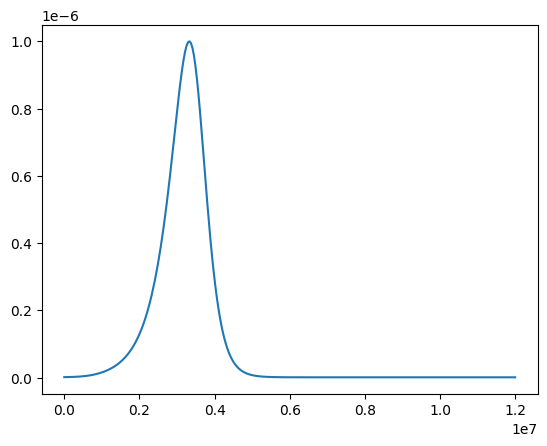

In [26]:
plt.plot(p_array,result_s)
plt.pause(1)

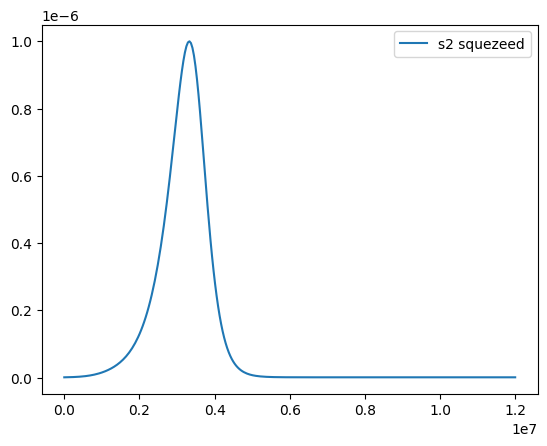

In [14]:
plt.plot(prev, s2, label = "s2 squezeed")
# plt.plot(prev, exprtk_eval, label = "ogs formula s2 squezeed")
plt.legend()
plt.pause(1)

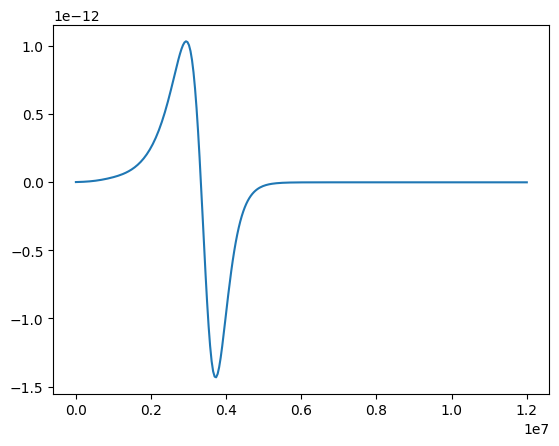

In [27]:
plt.plot(p_array,result_ds)
plt.pause(1)

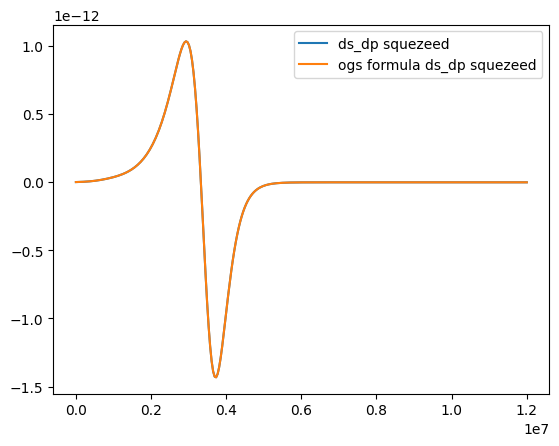

In [ ]:
plt.plot(prev, ds_dp, label = "ds_dp squezeed")
plt.plot(prev, exprtk_val_ds, label = "ogs formula ds_dp squezeed")
plt.legend()
plt.pause(1)

# Test prj mod

In [ ]:
temp_prj(prj_in="BH10_20180718_40.6_SA_sf.prj",
         prj_out="BH10_20180718_40.6_SA_sf_updated.prj",
         val_dict = val_dict,
         factors= factors)

found 1 nodes(s) matchin xpath_s
